In [21]:
#Prepare data
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn import datasets
from sklearn.model_selection import train_test_split

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def plot_decision_regions(x, y, classifier, test_idx=None, resolution=0.02):
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('red', 'blue', 'lightgreen', 'gray', 'cyan')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    x1_min, x1_max = x[:, 0].min() - 1, x[:, 0].max() + 1
    x2_min, x2_max = x[:, 1].min() - 1, x[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(
        np.arange(x1_min, x1_max, resolution),
        np.arange(x2_min, x2_max, resolution)
    )
    z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T)
    z = z.reshape(xx1.shape)

    plt.contourf(xx1, xx2, z, alpha=0.3, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(
            x=x[y == cl, 0],
            y=x[y == cl, 1],
            alpha=0.8,
            c=colors[idx],
            marker=markers[idx],
            label=f'Class {cl}',
            edgecolors='black' if markers[idx] != 'x' else None
        )

    if test_idx:
        x_test, y_test = x[test_idx, :], y[test_idx]
        plt.scatter(
            x_test[:, 0], x_test[:, 1],
            facecolors='none',
            edgecolors='black',
            alpha=1.0,
            linewidths=1,
            marker='o',
            s=100,
            label='test_set'
        )

In [23]:
iris = datasets.load_iris()
X = iris.data[:, [2,3]]
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

x_train_01_subset = X_train[(y_train == 0) | (y_train == 1)]
y_train_01_subset = y_train[(y_train == 0) | (y_train == 1)]

sc = StandardScaler()
sc.fit(x_train_01_subset)
x_train_std = sc.transform(X_train)
x_test_std = sc.transform(X_test)
x_combined_std = np.vstack((x_train_std, x_test_std))
y_combined = np.hstack((y_train, y_test))

In [24]:
from sklearn.tree import DecisionTreeClassifier
# Usamos plot_decision_regions que ya tienes definida en la celda BjtzCXH3XmPZ

tree = DecisionTreeClassifier(criterion='gini', max_depth=2, random_state=1)
tree.fit(X_train, y_train)

from sklearn.tree import export_text

# El modelo se entrenó con 2 características (longitud y ancho del pétalo)
rules = export_text(tree, feature_names=["petal length [cm]", "petal width [cm]"])
print(rules)

|--- petal width [cm] <= 0.75
|   |--- class: 0
|--- petal width [cm] >  0.75
|   |--- petal length [cm] <= 4.75
|   |   |--- class: 1
|   |--- petal length [cm] >  4.75
|   |   |--- class: 2



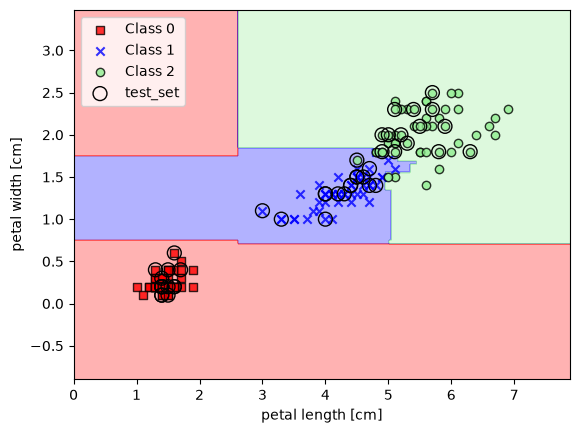

In [30]:
from sklearn.ensemble import RandomForestClassifier

x_combined = np.vstack((X_train, X_test))
y_combined = np.hstack((y_train, y_test))

forest = RandomForestClassifier(criterion='gini', n_estimators=67, random_state=1, n_jobs=-1)
forest.fit(X_train, y_train)

plot_decision_regions(x_combined, y_combined, classifier=forest, test_idx=range(105, 150))
plt.xlabel('petal length [cm]')
plt.ylabel('petal width [cm]')
plt.legend(loc='upper left')
plt.show()